# 01 — Exploratory Data Analysis: Air Raid Alerts in Ukraine
**Project:** Forecasting the spatio-temporal spread of air raid alerts across Ukrainian oblasts

Goals of this notebook:
1. Load the latest official alert history.
2. Clean it and turn it into one alert-episode table per oblast.
3. Build a regular time series grid (5 min × oblast).
4. Analyse trend, seasonality, autocorrelation and **spatial lead–lag** (does one oblast's alert predict another's?).
5. Fix the train/test split for later modelling (no leakage).

Data: [Vadimkin/ukrainian-air-raid-sirens-dataset](https://github.com/Vadimkin/ukrainian-air-raid-sirens-dataset) (official alerts.in.ua data).

In [1]:
# !pip install pandas numpy matplotlib seaborn statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
TZ = "Europe/Kyiv"
FREQ = "5min"          # grid step
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)

## 1. Load data

In [2]:
URL = ("https://raw.githubusercontent.com/Vadimkin/ukrainian-air-raid-sirens-dataset/"
       "main/datasets/official_data_en.csv")
raw_path = DATA_DIR / "official_data_en.csv"
if not raw_path.exists():
    import requests
    r = requests.get(URL, timeout=120); r.raise_for_status()
    raw_path.write_bytes(r.content)

raw = pd.read_csv(raw_path)
print(raw.shape)
raw.head()

(299275, 7)


,oblast,raion,hromada,level,started_at,finished_at,source
0,Vinnytska oblast,NaN,NaN,oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:50:07+00:00,official
1,Zhytomyrska oblast,NaN,NaN,oblast,2022-03-15 16:11:25+00:00,2022-03-15 16:54:23+00:00,official
2,Cherkaska oblast,Umanskyi raion,Umanska terytorialna hromada,hromada,2022-03-15 16:11:50+00:00,2022-03-15 16:54:47+00:00,official
3,Mykolaivska oblast,Pervomaiskyi raion,m. Pervomaisk ta Pervomaiska terytorialna hromada,hromada,2022-03-15 16:14:46+00:00,2022-03-15 16:57:08+00:00,official
4,Kirovohradska oblast,NaN,NaN,oblast,2022-03-15 16:15:11+00:00,2022-03-15 16:54:52+00:00,official


In [3]:
raw.info()
print(raw["level"].value_counts())
print("\nOblasts:", raw["oblast"].nunique())
raw["oblast"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 299275 entries, 0 to 299274
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   oblast       299275 non-null  str  
 1   raion        169040 non-null  str  
 2   hromada      36789 non-null   str  
 3   level        299275 non-null  str  
 4   started_at   299275 non-null  str  
 5   finished_at  299275 non-null  str  
 6   source       299275 non-null  str  
dtypes: str(7)
memory usage: 43.4 MB
level
raion      132251
oblast     130235
hromada     36789
Name: count, dtype: int64

Oblasts: 25


oblast
Dnipropetrovska oblast     45729
Kharkivska oblast          39651
Donetska oblast            28117
Zaporizka oblast           26744
Sumska oblast              21036
Poltavska oblast           15988
Mykolaivska oblast         15699
Chernihivska oblast        14899
Odeska oblast              13238
Khersonska oblast          12648
Kirovohradska oblast       11743
Kyivska oblast             10951
Cherkaska oblast           10370
Vinnytska oblast            5021
Zhytomyrska oblast          4711
Kyiv City                   4141
Khmelnytska oblast          2938
Rivnenska oblast            2742
Lvivska oblast              2380
Ivano-Frankivska oblast     2228
Volynska oblast             2169
Ternopilska oblast          2134
Zakarpatska oblast          2051
Chernivetska oblast         1945
Luhanska oblast                2
Name: count, dtype: int64

## 2. Cleaning

In [4]:
df = raw.copy()
df["started_at"]  = pd.to_datetime(df["started_at"],  utc=True).dt.tz_convert(TZ)
df["finished_at"] = pd.to_datetime(df["finished_at"], utc=True).dt.tz_convert(TZ)

n0 = len(df)
df = df.dropna(subset=["started_at", "finished_at"])
df = df[df["finished_at"] > df["started_at"]]
df["duration_min"] = (df["finished_at"] - df["started_at"]).dt.total_seconds() / 60
# alerts longer than 3 days are almost certainly 'stuck' records (e.g. occupied territories)
df = df[df["duration_min"] < 3 * 24 * 60]
print(f"dropped {n0 - len(df)} rows; kept {len(df)}")
print("period:", df["started_at"].min(), "→", df["started_at"].max())

dropped 179 rows; kept 299096
period: 2022-03-15 18:10:34+02:00 → 2026-09-07 08:28:22+03:00


/var/folders/r3/33hx78md7mndzn7cc02mj4s00000gn/T/ipykernel_39055/947159693.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  lvl = df.groupby([df["started_at"].dt.to_period("M"), "level"]).size().unstack(fill_value=0)


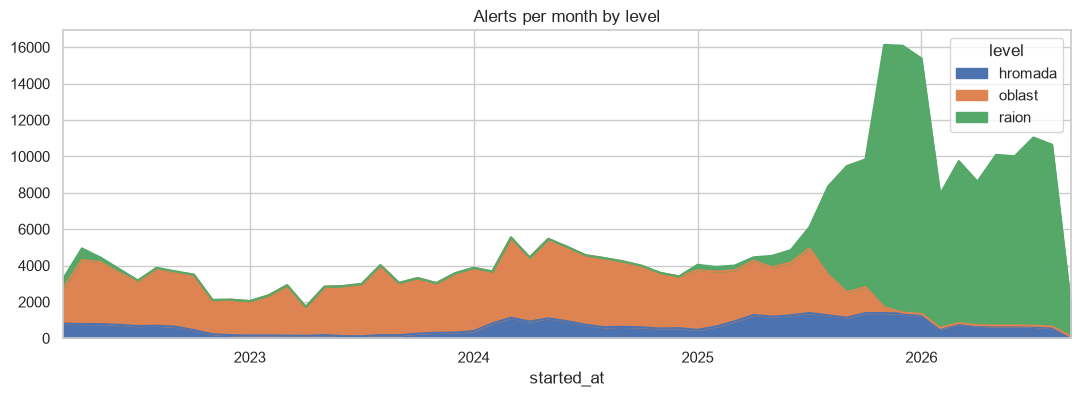

In [5]:
# How the reporting level changed over time (important: since 2023 many alerts are raion/hromada-level)
lvl = df.groupby([df["started_at"].dt.to_period("M"), "level"]).size().unstack(fill_value=0)
lvl.plot(kind="area", stacked=True, figsize=(13,4), title="Alerts per month by level")
plt.show()

### Oblast-level episodes
We define **"oblast X is on alert"** = an alert is active in *any part* of the oblast (oblast, raion or hromada level).
Overlapping intervals are merged into a single episode.

In [6]:
def merge_intervals(g):
    g = g.sort_values("started_at")
    s, e = g["started_at"].values, g["finished_at"].values
    run_end = np.maximum.accumulate(e)
    new = np.r_[True, s[1:] > run_end[:-1]]
    grp = np.cumsum(new)
    return pd.DataFrame({"start": pd.Series(s).groupby(grp).min().values,
                         "end":   pd.Series(run_end).groupby(grp).max().values})

ep = (df.groupby("oblast")[["started_at","finished_at"]]
        .apply(merge_intervals).reset_index(level=0).reset_index(drop=True))
ep["start"] = pd.to_datetime(ep["start"], utc=True).dt.tz_convert(TZ)
ep["end"]   = pd.to_datetime(ep["end"],   utc=True).dt.tz_convert(TZ)
ep["duration_min"] = (ep["end"] - ep["start"]).dt.total_seconds() / 60
print(len(ep), "episodes")
ep.head()

84009 episodes


,oblast,start,end,duration_min
0,Cherkaska oblast,2022-03-15 18:11:50+02:00,2022-03-15 18:54:47+02:00,42.950000
1,Cherkaska oblast,2022-03-15 20:04:27+02:00,2022-03-15 20:35:27+02:00,31.000000
2,Cherkaska oblast,2022-03-16 02:50:06+02:00,2022-03-16 06:42:26+02:00,232.333333
3,Cherkaska oblast,2022-03-16 11:47:38+02:00,2022-03-16 12:45:26+02:00,57.800000
4,Cherkaska oblast,2022-03-16 13:35:15+02:00,2022-03-16 15:12:46+02:00,97.516667


## 3. Basic statistics

In [7]:
stats = (ep.groupby("oblast")
            .agg(n_alerts=("start","size"),
                 median_dur_min=("duration_min","median"),
                 total_hours=("duration_min", lambda x: x.sum()/60))
            .sort_values("total_hours", ascending=False))
stats.round(1)

,n_alerts,median_dur_min,total_hours
oblast,,,
Dnipropetrovska oblast,3716,66.9,29569.8
Donetska oblast,7296,60.6,21231.5
Kharkivska oblast,8841,47.5,16472.5
Sumska oblast,6097,69.7,15265.5
Zaporizka oblast,8263,44.5,12798.5
Chernihivska oblast,4183,62.1,10301.5
Poltavska oblast,5912,37.8,8333.2
Mykolaivska oblast,5500,38.9,6162.5
Khersonska oblast,5229,38.3,5988.9


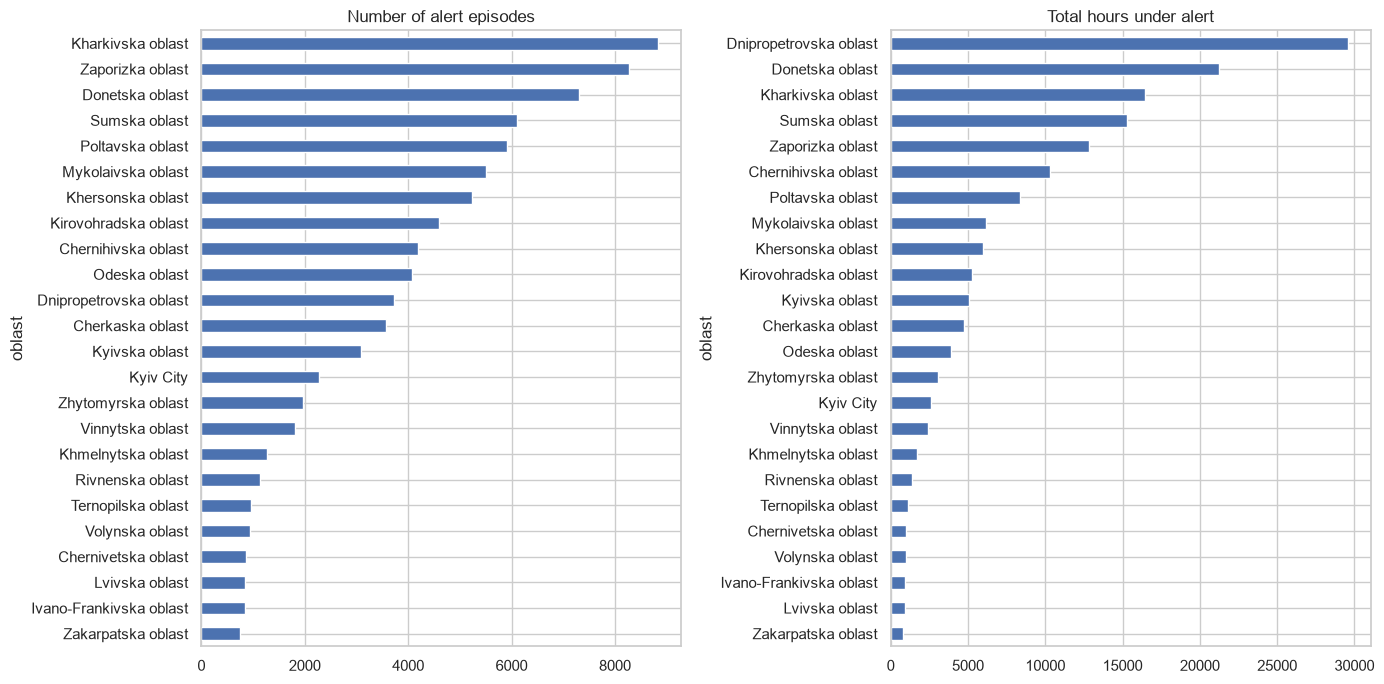

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
stats["n_alerts"].sort_values().plot.barh(ax=ax[0], title="Number of alert episodes")
stats["total_hours"].sort_values().plot.barh(ax=ax[1], title="Total hours under alert")
plt.tight_layout(); plt.show()

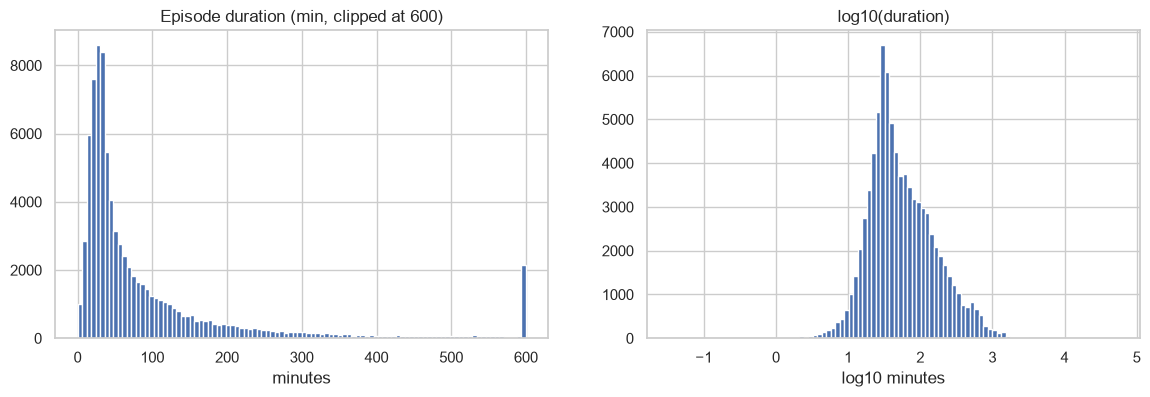

count    84009.0
mean       115.7
std        433.1
min          0.0
25%         26.7
50%         45.0
75%        106.8
90%        237.2
99%        925.7
max      54712.7
Name: duration_min, dtype: float64

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ep["duration_min"].clip(upper=600).hist(bins=100, ax=ax[0])
ax[0].set(title="Episode duration (min, clipped at 600)", xlabel="minutes")
np.log10(ep["duration_min"]).hist(bins=100, ax=ax[1])
ax[1].set(title="log10(duration)", xlabel="log10 minutes")
plt.show()
ep["duration_min"].describe(percentiles=[.25,.5,.75,.9,.99]).round(1)

## 4. Regular time series grid (5 min × oblast)

In [10]:
t0 = ep["start"].min().floor(FREQ)
t1 = ep["end"].max().ceil(FREQ)
grid = pd.date_range(t0, t1, freq=FREQ)
step = pd.Timedelta(FREQ)
oblasts = sorted(ep["oblast"].unique())

def to_state(e):
    arr = np.zeros(len(grid) + 1, dtype=np.int32)
    i0 = ((e["start"] - t0) // step).astype(int).values
    i1 = np.ceil((e["end"] - t0) / step).astype(int).values
    np.add.at(arr, i0, 1); np.add.at(arr, i1, -1)
    return (np.cumsum(arr)[:-1] > 0).astype(np.int8)

def to_starts(e):
    arr = np.zeros(len(grid), dtype=np.int8)
    arr[((e["start"] - t0) // step).astype(int).values] = 1
    return arr

state  = pd.DataFrame({o: to_state(ep[ep.oblast == o])  for o in oblasts}, index=grid)
starts = pd.DataFrame({o: to_starts(ep[ep.oblast == o]) for o in oblasts}, index=grid)
print(state.shape)
state.mean().sort_values(ascending=False).round(3).head(10)  # share of time under alert

(471331, 24)


Dnipropetrovska oblast    0.760
Donetska oblast           0.556
Kharkivska oblast         0.438
Sumska oblast             0.401
Zaporizka oblast          0.343
Chernihivska oblast       0.271
Poltavska oblast          0.224
Mykolaivska oblast        0.168
Khersonska oblast         0.163
Kirovohradska oblast      0.144
dtype: float64

## 5. Trend: how many oblasts are on alert at once

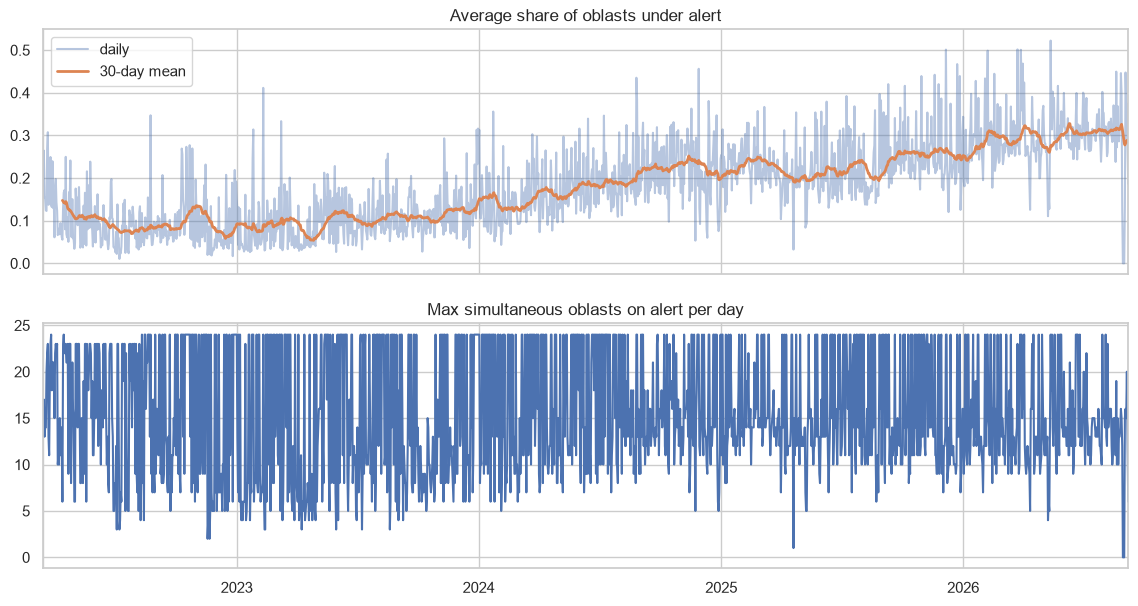

In [11]:
n_active = state.sum(axis=1)
daily = state.resample("D").mean().mean(axis=1)   # avg share of oblasts on alert

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
daily.plot(ax=ax[0], alpha=.4, label="daily")
daily.rolling(30).mean().plot(ax=ax[0], lw=2, label="30-day mean")
ax[0].set(title="Average share of oblasts under alert"); ax[0].legend()
n_active.resample("D").max().plot(ax=ax[1], title="Max simultaneous oblasts on alert per day")
plt.show()

742 large-scale days


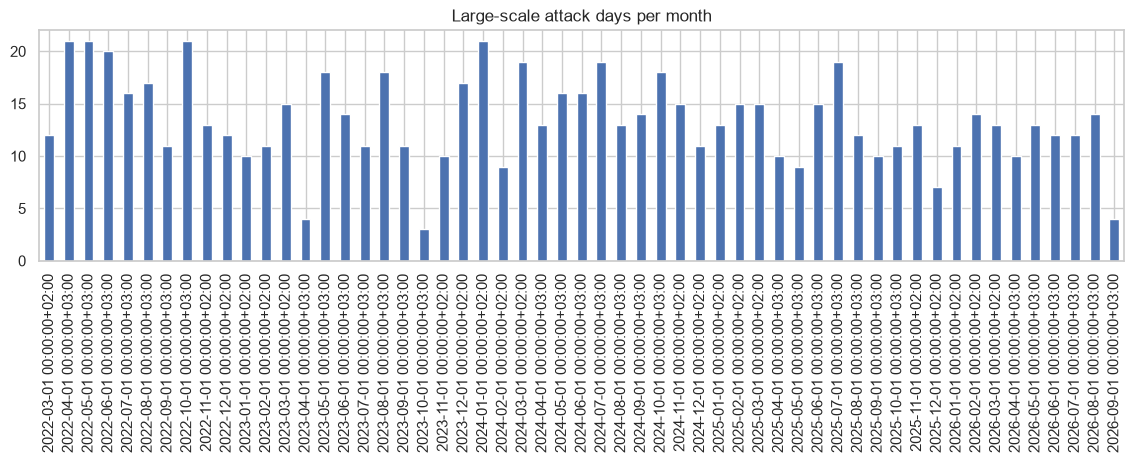

In [12]:
# Large-scale attacks: days where ≥ 15 oblasts were on alert simultaneously
big = n_active.resample("D").max()
big_days = big[big >= 15]
print(len(big_days), "large-scale days")
big_days.resample("MS").size().plot(kind="bar", figsize=(14,3), title="Large-scale attack days per month")
plt.show()

## 6. Seasonality: hour of day × day of week

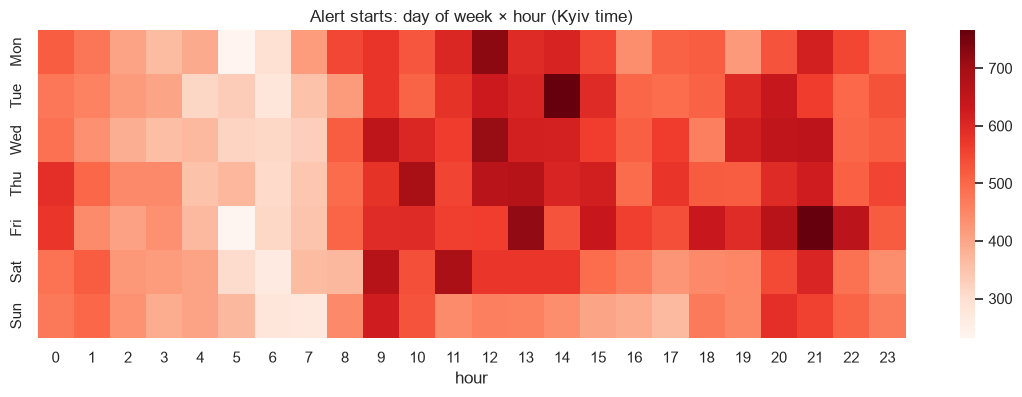

In [13]:
s = ep.assign(hour=ep["start"].dt.hour, dow=ep["start"].dt.dayofweek)
heat = s.pivot_table(index="dow", columns="hour", values="start", aggfunc="size")
heat.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
plt.figure(figsize=(14,4))
sns.heatmap(heat, cmap="Reds"); plt.title("Alert starts: day of week × hour (Kyiv time)")
plt.show()

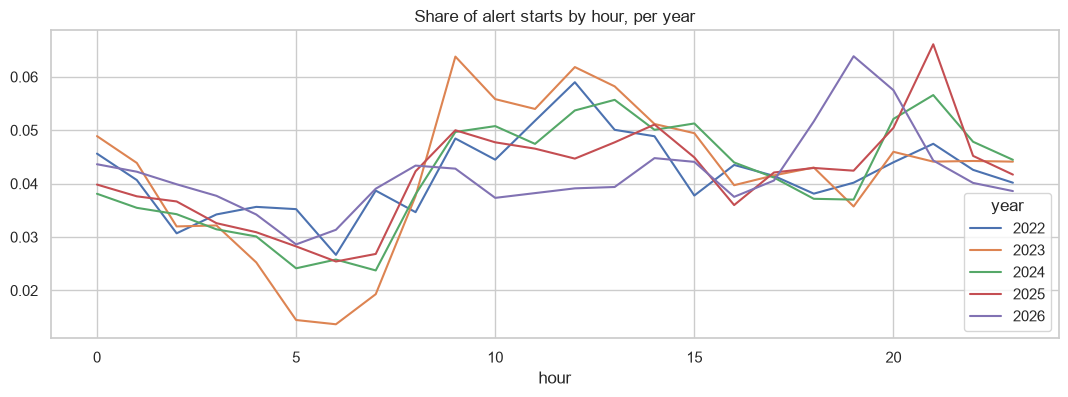

In [14]:
# Hourly profile per year — tactics change over time (e.g. more night drone attacks)
s["year"] = s["start"].dt.year
s.pivot_table(index="hour", columns="year", values="start", aggfunc="size") \
 .div(s.groupby("year").size(), axis=1) \
 .plot(figsize=(13,4), title="Share of alert starts by hour, per year")
plt.show()

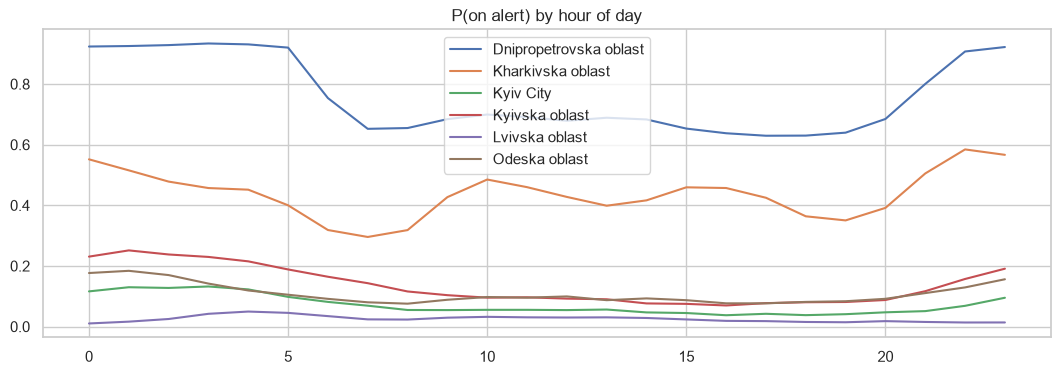

In [15]:
# Probability of alert by hour for selected oblasts
sel = [o for o in oblasts if any(k in o for k in ["Kyiv", "Kharkiv", "Lviv", "Odes", "Dnipro"])]
state[sel].groupby(state.index.hour).mean().plot(figsize=(13,4), title="P(on alert) by hour of day")
plt.show()

## 7. Autocorrelation (temporal dependence)
Using the most recent year at hourly resolution.

target: Kyiv City


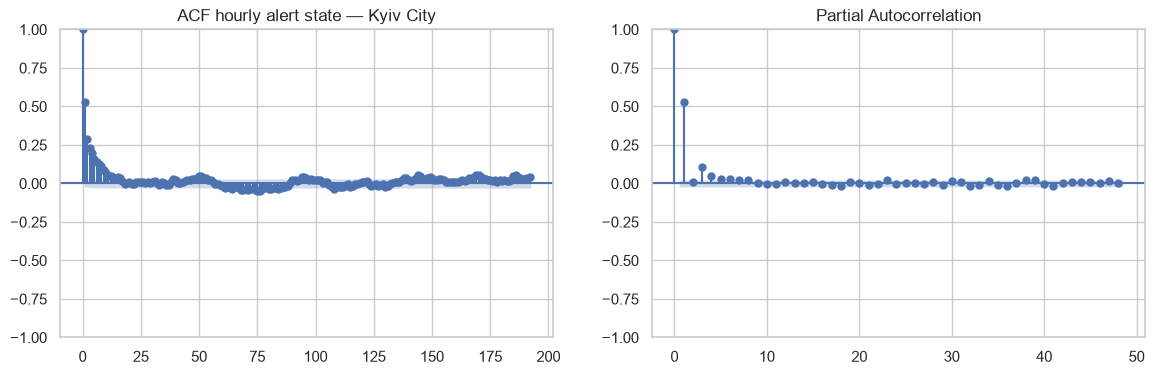

In [16]:
TARGET = next(o for o in oblasts if o.startswith("Kyiv") and "City" in o) if any("City" in o for o in oblasts) \
         else next(o for o in oblasts if o.startswith("Kyiv"))
print("target:", TARGET)

recent = state.loc[state.index.max() - pd.Timedelta(days=365):]
hourly = recent[TARGET].resample("h").max()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(hourly, lags=24*8, ax=ax[0]); ax[0].set_title(f"ACF hourly alert state — {TARGET}")
plot_pacf(hourly, lags=48, ax=ax[1], method="ywm")
plt.show()

## 8. Spatial lead–lag analysis (core of the propagation model)
For every pair of oblasts (A → B):

**lift(A→B) = P(B starts within 30 min after A starts) / P(B starts in a random 30-min window)**

Lift ≫ 1 means alerts in A are an early-warning signal for B.

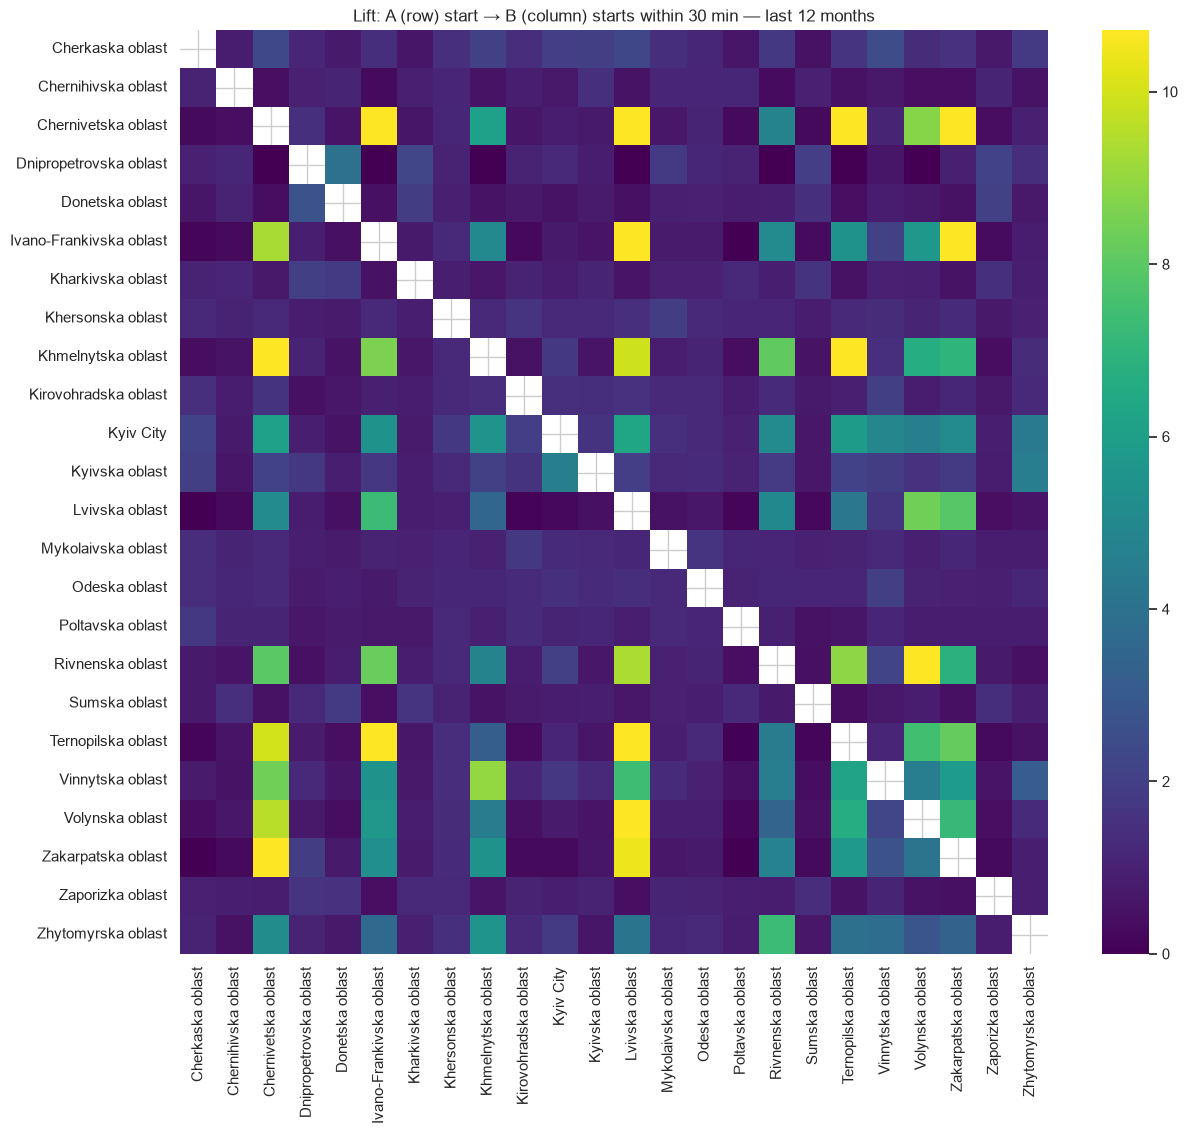

In [17]:
H = int(pd.Timedelta("30min") / step)   # horizon in steps
S = starts.loc[recent.index]             # last 12 months

# future_B[t] = 1 if B starts in (t, t+H]
future = S[::-1].rolling(H, min_periods=1).max()[::-1].shift(-1).fillna(0)

base = future.mean()
lift = pd.DataFrame(index=oblasts, columns=oblasts, dtype=float)
for a in oblasts:
    mask = S[a] == 1
    if mask.sum() < 20: continue
    lift.loc[a] = future[mask].mean() / base
lift = lift.mask(np.eye(len(oblasts), dtype=bool))

plt.figure(figsize=(14, 12))
sns.heatmap(lift.astype(float), cmap="viridis", vmax=lift.stack().quantile(.98))
plt.title("Lift: A (row) start → B (column) starts within 30 min — last 12 months")
plt.show()

In [18]:
# Which oblasts best "warn" the target?
lift[TARGET].sort_values(ascending=False).head(10).round(2)

Kyivska oblast            4.60
Rivnenska oblast          2.05
Cherkaska oblast          1.95
Zhytomyrska oblast        1.81
Khmelnytska oblast        1.74
Vinnytska oblast          1.69
Odeska oblast             1.49
Kirovohradska oblast      1.46
Mykolaivska oblast        1.27
Dnipropetrovska oblast    1.24
Name: Kyiv City, dtype: float64

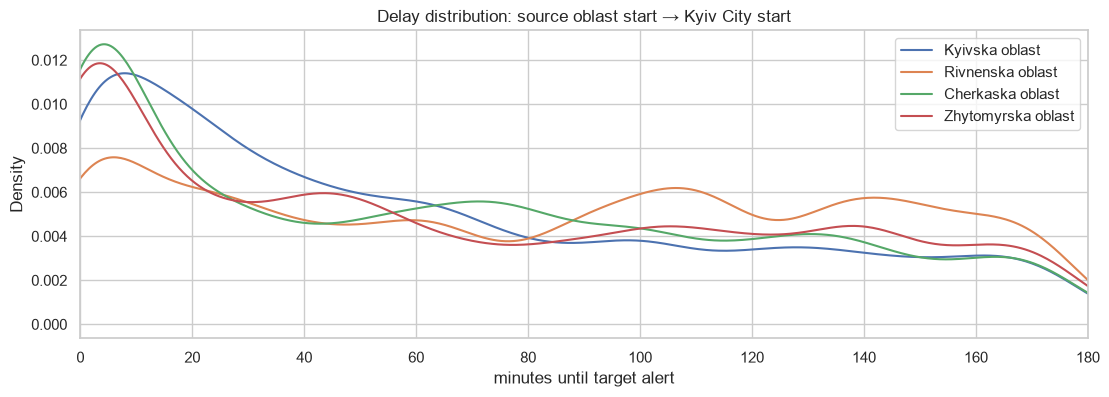

In [19]:
# Typical delay: for each start of A, the first start of TARGET in the next 3h
def lags(a, b, max_h="3h"):
    sa = ep[(ep.oblast == a)]["start"].sort_values()
    sb = ep[(ep.oblast == b)]["start"].sort_values()
    m = pd.merge_asof(sa.to_frame("ta"), sb.to_frame("tb"), left_on="ta", right_on="tb",
                      direction="forward", tolerance=pd.Timedelta(max_h)).dropna()
    return (m["tb"] - m["ta"]).dt.total_seconds() / 60

top = lift[TARGET].sort_values(ascending=False).head(4).index
plt.figure(figsize=(13,4))
for a in top:
    lags(a, TARGET).clip(upper=180).plot.kde(label=a, bw_method=.15)
plt.xlim(0, 180); plt.xlabel("minutes until target alert"); plt.legend()
plt.title(f"Delay distribution: source oblast start → {TARGET} start")
plt.show()

## 9. Co-occurrence: correlation of alert states

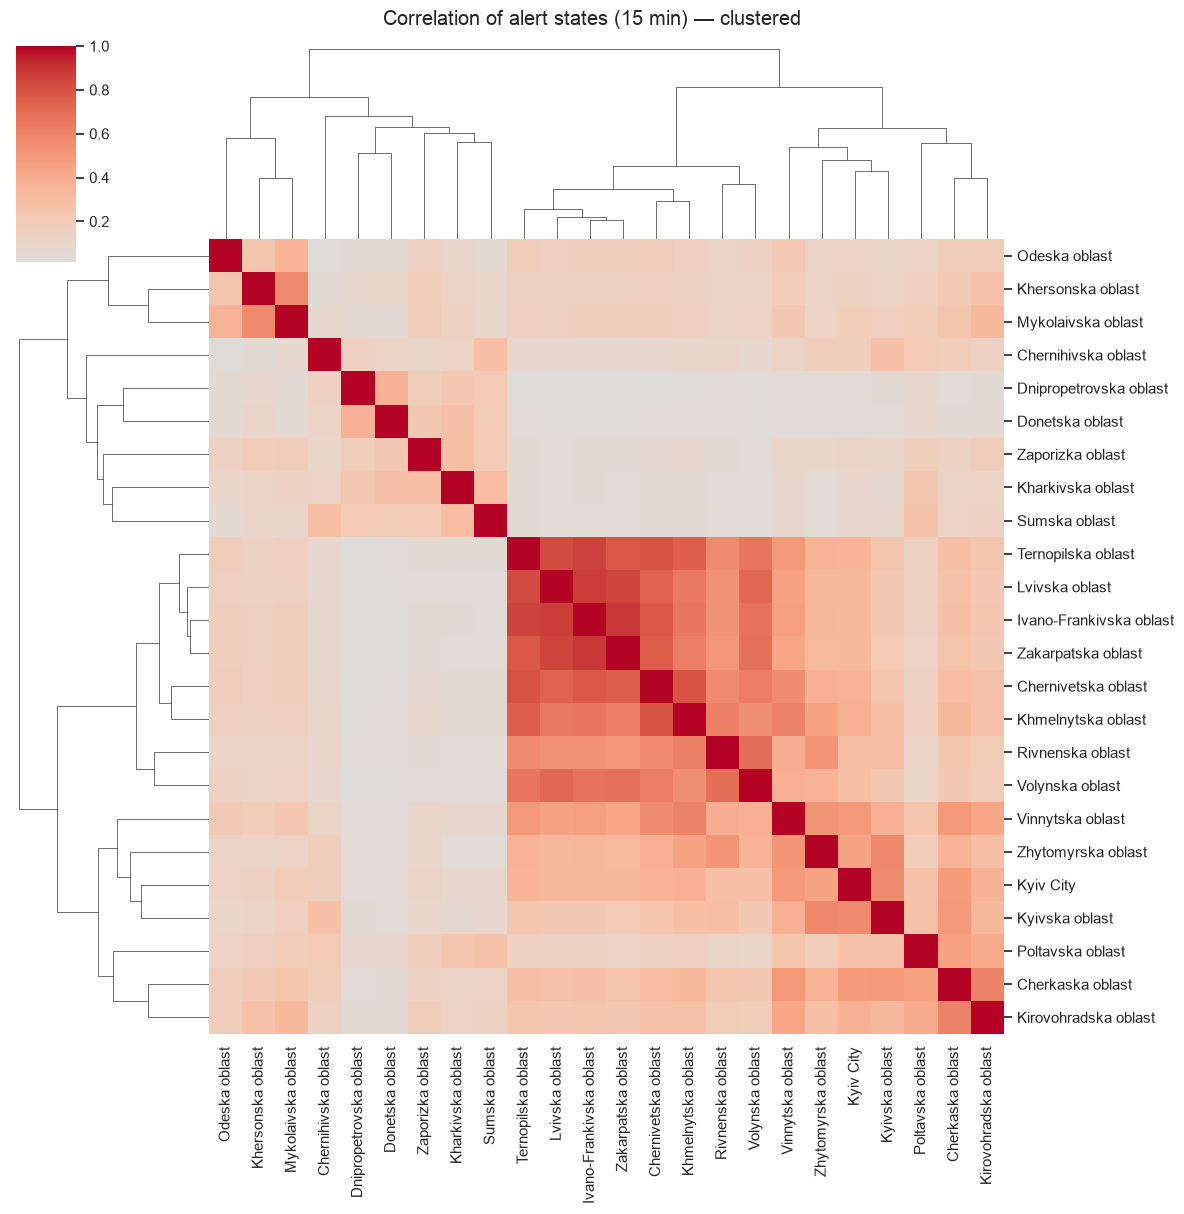

In [20]:
corr = recent.resample("15min").max().corr()
g = sns.clustermap(corr, cmap="coolwarm", center=0, figsize=(12,12))
g.fig.suptitle("Correlation of alert states (15 min) — clustered", y=1.01)
plt.show()

## 10. Train / validation / test split (no leakage)
Time-based only. The most recent period is the test set.

train: …            → 2026-07-09 00:00:00+03:00
val  : 2026-07-09 00:00:00+03:00 → 2026-08-08 00:00:00+03:00
test : 2026-08-08 00:00:00+03:00 → 2026-09-07 08:40:00+03:00


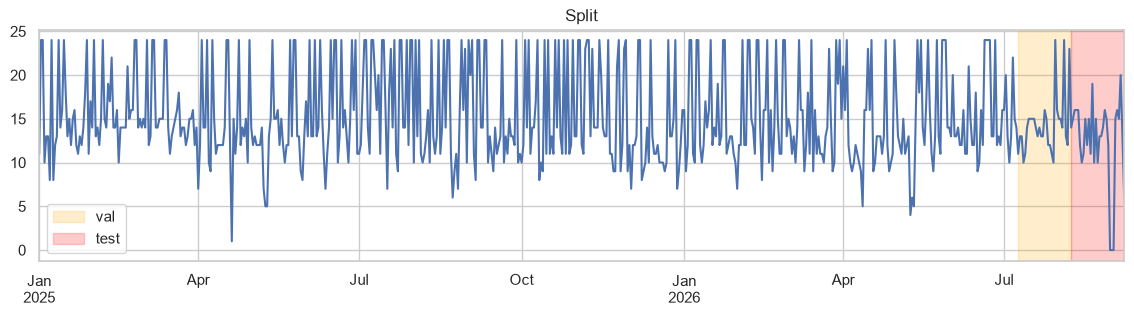

In [21]:
END = state.index.max()
TEST_START = (END - pd.Timedelta(days=30)).normalize()
VAL_START  = (TEST_START - pd.Timedelta(days=30)).normalize()
print("train: …            →", VAL_START)
print("val  :", VAL_START, "→", TEST_START)
print("test :", TEST_START, "→", END)

ax = n_active.resample("D").max().loc["2025":].plot(figsize=(14,3), title="Split")
ax.axvspan(VAL_START, TEST_START, color="orange", alpha=.2, label="val")
ax.axvspan(TEST_START, END, color="red", alpha=.2, label="test"); ax.legend()
plt.show()

In [22]:
# Save processed data for the modelling notebooks
state.to_parquet(DATA_DIR / "state_5min.parquet")
starts.to_parquet(DATA_DIR / "starts_5min.parquet")
ep.to_parquet(DATA_DIR / "episodes.parquet")
pd.Series({"val_start": str(VAL_START), "test_start": str(TEST_START)}).to_json(DATA_DIR / "split.json")
print("saved")

saved


## Key takeaways (fill in after running)
- **Trend:** …
- **Seasonality:** daily / weekly pattern …
- **Autocorrelation:** …
- **Spatial lead–lag:** top early-warning oblasts for Kyiv are … with typical delay of … min.
- **Implication for modelling:** neighbour-alert features and recent history should be strong predictors → motivates graph / Hawkes model.